# Implement a custom pywearable loader

A loader adapts one project or provider to pywearable's canonical
schemas. Domain functions then calculate features without knowing
the original file names or field conventions.

Here we implement `WyvernLoader` for the **Wyvern Band**, a fictional
wearable. The example export contains three participants and seven
days, with deliberately inconsistent field names, units, and file
formats.

We will inspect the provider files, translate deliberately
inconsistent fields into canonical schemas, validate the loader
boundary, and then use the normal feature and visualization APIs.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src" / "pywearable").is_dir():
    REPO_ROOT = next(
        parent
        for parent in Path.cwd().resolve().parents
        if (parent / "src" / "pywearable").is_dir()
    )
sys.path.insert(0, str(REPO_ROOT / "src"))

from pywearable import (
    activity,
    heart_rate,
    provider_features,
    respiration,
    schema,
    sleep,
    visualization,
)
from pywearable.loader import BaseLoader

DATA_ROOT = REPO_ROOT / "docs" / "_notebooks" / "mock_provider_data"
START = pd.Timestamp("2026-03-02")
END = pd.Timestamp("2026-03-09")

WYVERN_SLEEP_HEALTH_SCORE = "wyvern_sleep_health_score"
WYVERN_DAILY_STRAIN_SCORE = "wyvern_daily_strain_score"

## Inspect the fictional provider export

The export uses one directory per participant and mixes TSV, CSV,
and JSON files. Source names mix camel case and snake case, and
none is assumed to be canonical.

In [2]:
participant_dirs = sorted(
    path for path in DATA_ROOT.glob("demo-*") if path.is_dir()
)
participants_source = pd.concat(
    [
        pd.read_csv(path / "participant.tsv", sep="	")
        for path in participant_dirs
    ],
    ignore_index=True,
)
pulse_source = pd.concat(
    [
        pd.read_csv(path / "pulse.tsv", sep="	")
        for path in participant_dirs
    ],
    ignore_index=True,
)
movement_source = pd.concat(
    [pd.read_csv(path / "movement.csv") for path in participant_dirs],
    ignore_index=True,
)
sleep_source = pd.json_normalize(
    [
        night
        for path in participant_dirs
        for night in json.loads(
            (path / "sleep.json").read_text()
        )["nights"]
    ]
)
score_source = pd.DataFrame(
    [
        record
        for path in participant_dirs
        for record in json.loads(
            (path / "daily_scores.json").read_text()
        )["records"]
    ]
)
inventory = pd.DataFrame(
    [
        ("demo-*/participant.tsv", "TSV", len(participant_dirs), len(participants_source)),
        ("demo-*/pulse.tsv", "TSV", len(participant_dirs), len(pulse_source)),
        ("demo-*/movement.csv", "CSV", len(participant_dirs), len(movement_source)),
        ("demo-*/sleep.json", "JSON", len(participant_dirs), len(sleep_source)),
        ("demo-*/daily_scores.json", "JSON", len(participant_dirs), len(score_source)),
    ],
    columns=["path pattern", "format", "files", "records"],
)

display(inventory)
display(
    pulse_source.head(3),
    movement_source.head(3),
    sleep_source[
        [
            "memberCode",
            "sleepDate",
            "startedAt",
            "sleepSeconds",
            "nightlyRespiration.meanBreathsPerMinute",
        ]
    ].head(3),
    score_source.head(3),
)

,path pattern,format,files,records
0,demo-*/participant.tsv,TSV,3,3
1,demo-*/pulse.tsv,TSV,3,26499
2,demo-*/movement.csv,CSV,3,1857
3,demo-*/sleep.json,JSON,3,19
4,demo-*/daily_scores.json,JSON,3,21


,memberCode,capturedAtLocal,utcOffsetMinutes,pulseBpm,readingQuality
0,demo-01,2026-03-02T00:00,60,52,good
1,demo-01,2026-03-02T00:01,60,52,good
2,demo-01,2026-03-02T00:02,60,54,good


,member_code,intervalStart,intervalSeconds,stepCount
0,demo-01,2026-03-02T00:00,900,0.0
1,demo-01,2026-03-02T00:15,900,0.0
2,demo-01,2026-03-02T00:30,900,0.0


,memberCode,sleepDate,startedAt,sleepSeconds,nightlyRespiration.meanBreathsPerMinute
0,demo-01,2026-03-02,2026-03-01T23:22:00,28200,14.8
1,demo-01,2026-03-03,2026-03-02T23:47:00,27540,14.8
2,demo-01,2026-03-04,2026-03-03T22:51:00,29880,16.7


,memberCode,day,sleepHealthScore,dailyStrain_score
0,demo-01,2026-03-02,80.0,63
1,demo-01,2026-03-03,79.0,69
2,demo-01,2026-03-04,77.0,71


## Plan the translation

| Source field | Canonical field | Conversion |
|---|---|---|
| `capturedAtLocal`, `utcOffsetMinutes`, `pulseBpm` | `local_time`, `utc_time`, `timezone`, `heart_rate` | Parse the local clock, subtract the offset for UTC, and retain numeric beats per minute. |
| `movement.csv`: `intervalStart`, `intervalSeconds`, `stepCount`; `participant.tsv`: `utcOffsetMinutes` | `local_time`, `utc_time`, `timezone`, `duration_in_ms`, `activity_steps` | Use the participant metadata offset for both clocks, convert seconds to milliseconds, and preserve zero-step intervals. |
| `nightKey`, `sleepDate`, `startedAt`, `endedAt` | `sleep_summary_id`, `calendar_date`, `local_time`, `local_end_time` | Retain the provider's night identifier and sleep-calendar label; parse session bounds. |
| `sleepSeconds`, `awakeSeconds`, `unmeasurableSeconds`, stage totals | `duration_in_ms`, `awake_duration_in_ms`, `unmeasurable_sleep_duration_in_ms`, `light_sleep_duration_in_ms`, `deep_sleep_duration_in_ms`, `rem_sleep_duration_in_ms` | Convert seconds to milliseconds and aggregate stage durations by night. |
| `stageSegments[].startedAt`, `durationSeconds`, `stageCode` | `local_time`, `duration_in_ms`, `type`, linked by `sleep_summary_id` | Flatten stage intervals and map provider codes to canonical sleep-stage values. |
| `nightlyRespiration.meanBreathsPerMinute`, `stdBreathsPerMinute` | `respiratory_rate_mean`, `respiratory_rate_std`, indexed by `calendar_date` | Expose the available nightly summary without inventing respiration samples. |
| `sleepHealthScore` | `overall_sleep_score` and `wyvern_sleep_health_score` | Make the score available in sleep views while retaining its provider-native feature name. |
| `dailyStrain_score` | `wyvern_daily_strain_score` | Retain the fictional provider prefix and native daily grain. |

A `BaseLoader` subclass implements the required sleep and
heart-rate methods. Optional methods are added only for streams
present in the export. Capability attributes tell pywearable which
clocks and source grains are available.

## Implement the adapter

Each method returns canonical columns and applies `[start_date,
end_date)` to the clock documented by that method. Schema preparers
normalize types, add optional columns, and validate required fields.
Returning a typed empty canonical frame is preferable to inventing
observations when a supported interval has no rows.

In [3]:
class WyvernLoader(BaseLoader):
    '''Adapt participant-folder exports from the fictional Wyvern Band.'''

    activity_source = "samples"
    activity_primary_resolution = "15min"
    activity_time_columns = (schema.UTC_TIME_COL, schema.LOCAL_TIME_COL)
    heart_rate_time_columns = (schema.UTC_TIME_COL, schema.LOCAL_TIME_COL)
    respiratory_rate_source = "provider_summary"
    provider_features = frozenset(
        {WYVERN_SLEEP_HEALTH_SCORE, WYVERN_DAILY_STRAIN_SCORE}
    )
    provider_feature_definitions = {
        WYVERN_SLEEP_HEALTH_SCORE: {"grain": "daily", "numeric": True},
        WYVERN_DAILY_STRAIN_SCORE: {"grain": "daily", "numeric": True},
    }

    _stage_codes = {
        "AWK": schema.SLEEP_STAGE_AWAKE_STAGE_VALUE,
        "LT": schema.SLEEP_STAGE_LIGHT_STAGE_VALUE,
        "DP": schema.SLEEP_STAGE_DEEP_STAGE_VALUE,
        "REM": schema.SLEEP_STAGE_REM_STAGE_VALUE,
        "UNM": schema.SLEEP_STAGE_UNMEASURABLE_STAGE_VALUE,
        "ASL": "asleep",
    }

    def __init__(self, data_root):
        '''Read every participant directory into source-shaped tables.

        Each ``demo-*`` directory is self-contained. TSV, CSV, and
        JSON records are concatenated here, but no canonical
        conversion occurs until a ``load_*`` method is called.
        '''
        data_root = Path(data_root)
        participant_dirs = sorted(
            path for path in data_root.glob("demo-*") if path.is_dir()
        )
        self._participants = pd.concat(
            [
                pd.read_csv(path / "participant.tsv", sep="	")
                for path in participant_dirs
            ],
            ignore_index=True,
        )
        self._heart_rate = pd.concat(
            [
                pd.read_csv(path / "pulse.tsv", sep="	")
                for path in participant_dirs
            ],
            ignore_index=True,
        )
        self._activity = pd.concat(
            [pd.read_csv(path / "movement.csv") for path in participant_dirs],
            ignore_index=True,
        )

        sleep_nights = [
            night
            for path in participant_dirs
            for night in json.loads(
                (path / "sleep.json").read_text()
            )["nights"]
        ]
        self._sleep = pd.json_normalize(sleep_nights)
        stage_rows = []
        for night in sleep_nights:
            for segment in night["stageSegments"]:
                stage_rows.append(
                    {
                        "memberCode": night["memberCode"],
                        "nightKey": night["nightKey"],
                        **segment,
                    }
                )
        self._stages = pd.DataFrame(stage_rows)

        self._scores = pd.DataFrame(
            [
                record
                for path in participant_dirs
                for record in json.loads(
                    (path / "daily_scores.json").read_text()
                )["records"]
            ]
        )

    def get_user_ids(self):
        '''Return participant identifiers read from ``participant.tsv``.'''
        return sorted(self._participants["memberCode"].unique())

    @staticmethod
    def _filter(frame, column, start_date, end_date):
        '''Apply half-open ``[start_date, end_date)`` canonical bounds.'''
        values = pd.to_datetime(frame[column])
        mask = pd.Series(True, index=frame.index)
        if start_date is not None:
            mask &= values >= pd.Timestamp(start_date)
        if end_date is not None:
            mask &= values < pd.Timestamp(end_date)
        return frame.loc[mask].copy()

    @staticmethod
    def _utc_from_local(local_time, offset_minutes):
        '''Subtract provider UTC offsets from naive local timestamps.'''
        return pd.to_datetime(local_time) - pd.to_timedelta(
            offset_minutes, unit="m"
        )

    def load_heart_rate(
        self,
        user_id,
        start_date=None,
        end_date=None,
        time_col=schema.LOCAL_TIME_COL,
    ):
        '''Convert ``pulse.tsv`` rows to canonical heart-rate samples.

        ``capturedAtLocal`` becomes ``local_time``; the per-row
        minute offset supplies both ``timezone`` and ``utc_time``;
        ``pulseBpm`` becomes numeric ``heart_rate``. Filtering uses
        the caller-selected canonical clock.
        '''
        rows = self._heart_rate[
            self._heart_rate["memberCode"].eq(user_id)
        ].copy()
        local_time = pd.to_datetime(rows["capturedAtLocal"])
        offsets = pd.to_timedelta(rows["utcOffsetMinutes"], unit="m")
        canonical = pd.DataFrame(
            {
                schema.UTC_TIME_COL: self._utc_from_local(
                    local_time, rows["utcOffsetMinutes"]
                ),
                schema.LOCAL_TIME_COL: local_time,
                schema.TIMEZONE_COL: offsets,
                schema.HEART_RATE_COL: rows["pulseBpm"],
            }
        )
        canonical = schema.prepare_heart_rate_samples(canonical)
        return self._filter(canonical, time_col, start_date, end_date)

    def load_activity_samples(self, user_id, start_date=None, end_date=None, **kwargs):
        '''Convert ``movement.csv`` intervals to canonical activity samples.

        The participant metadata supplies the UTC offset missing
        from each movement row. ``intervalSeconds`` is converted to
        ``duration_in_ms`` and ``stepCount`` to ``activity_steps``;
        observed zero-step intervals remain observations, not nulls.
        '''
        rows = self._activity[
            self._activity["member_code"].eq(user_id)
        ].copy()
        local_time = pd.to_datetime(rows["intervalStart"])
        offset_minutes = self._participants.set_index("memberCode").loc[
            user_id, "utcOffsetMinutes"
        ]
        canonical = pd.DataFrame(
            {
                schema.UTC_TIME_COL: self._utc_from_local(
                    local_time, offset_minutes
                ),
                schema.LOCAL_TIME_COL: local_time,
                schema.TIMEZONE_COL: pd.to_timedelta(
                    offset_minutes, unit="m"
                ),
                schema.DURATION_IN_MS_COL: rows["intervalSeconds"] * 1_000,
                schema.ACTIVITY_STEPS_COL: rows["stepCount"],
            }
        )
        canonical = schema.prepare_activity_samples(canonical)
        return self._filter(
            canonical, schema.LOCAL_TIME_COL, start_date, end_date
        )

    def load_sleep_summary(self, user_id, start_date=None, end_date=None, drop_duplicates=True):
        '''Convert nightly JSON records to canonical sleep summaries.

        Provider session identifiers, calendar labels, and local
        bounds are retained. Durations are converted from seconds
        to milliseconds, flattened stage intervals are totaled by
        type, and ``sleepHealthScore`` is joined as canonical
        ``overall_sleep_score`` for sleep-specific displays.
        '''
        rows = self._sleep[self._sleep["memberCode"].eq(user_id)].copy()
        score_rows = self._scores[
            self._scores["memberCode"].eq(user_id)
        ][["memberCode", "day", "sleepHealthScore"]]
        rows = rows.merge(
            score_rows,
            left_on=["memberCode", "sleepDate"],
            right_on=["memberCode", "day"],
            how="left",
        )
        stage_totals = (
            self._stages[self._stages["memberCode"].eq(user_id)]
            .groupby(["nightKey", "stageCode"])["durationSeconds"]
            .sum()
            .unstack(fill_value=0)
        )
        rows = rows.merge(stage_totals, on="nightKey", how="left")

        def stage_duration(code):
            return rows.get(code, pd.Series(0, index=rows.index)) * 1_000

        canonical = pd.DataFrame(
            {
                schema.SLEEP_SUMMARY_ID_COL: rows["nightKey"],
                schema.CALENDAR_DATE_COL: rows["sleepDate"],
                schema.LOCAL_TIME_COL: rows["startedAt"],
                schema.LOCAL_END_TIME_COL: rows["endedAt"],
                schema.DURATION_IN_MS_COL: rows["sleepSeconds"] * 1_000,
                schema.SLEEP_SUMMARY_AWAKE_DURATION_IN_MS_COL: rows["awakeSeconds"] * 1_000,
                schema.SLEEP_SUMMARY_UNMEASURABLE_SLEEP_DURATION_IN_MS_COL: rows["unmeasurableSeconds"] * 1_000,
                schema.SLEEP_SUMMARY_LIGHT_SLEEP_DURATION_IN_MS_COL: stage_duration("LT"),
                schema.SLEEP_SUMMARY_DEEP_SLEEP_DURATION_IN_MS_COL: stage_duration("DP"),
                schema.SLEEP_SUMMARY_REM_SLEEP_DURATION_IN_MS_COL: stage_duration("REM"),
                schema.SLEEP_SUMMARY_OVERALL_SLEEP_SCORE_COL: rows["sleepHealthScore"],
            }
        )
        canonical = schema.prepare_sleep_summary(canonical)
        canonical = self._filter(
            canonical, schema.CALENDAR_DATE_COL, start_date, end_date
        )
        if drop_duplicates:
            canonical = canonical.drop_duplicates(schema.CALENDAR_DATE_COL)
        return canonical.reset_index(drop=True)

    def load_sleep_stage(self, user_id, start_date=None, end_date=None):
        '''Convert flattened stage segments to canonical intervals.

        ``startedAt`` becomes ``local_time``, seconds become
        ``duration_in_ms``, and Wyvern stage codes map to canonical
        ``type`` values. ``nightKey`` preserves the required link
        to ``sleep_summary_id``. Bounds use interval overlap.
        '''
        rows = self._stages[
            self._stages["memberCode"].eq(user_id)
        ].copy()
        canonical = pd.DataFrame(
            {
                schema.SLEEP_SUMMARY_ID_COL: rows["nightKey"],
                schema.LOCAL_TIME_COL: rows["startedAt"],
                schema.DURATION_IN_MS_COL: rows["durationSeconds"] * 1_000,
                schema.SLEEP_STAGE_SLEEP_TYPE_COL: rows["stageCode"].map(
                    self._stage_codes
                ),
            }
        )
        canonical = schema.prepare_sleep_stages(canonical)
        stage_end = canonical[schema.LOCAL_TIME_COL] + pd.to_timedelta(
            canonical[schema.DURATION_IN_MS_COL], unit="ms"
        )
        mask = pd.Series(True, index=canonical.index)
        if start_date is not None:
            mask &= stage_end > pd.Timestamp(start_date)
        if end_date is not None:
            mask &= canonical[schema.LOCAL_TIME_COL] < pd.Timestamp(end_date)
        return canonical.loc[mask].reset_index(drop=True)

    def load_respiration_summary(
        self, user_id, start_date=None, end_date=None
    ):
        '''Expose the nightly respiration summary stored in ``sleep.json``.

        The two provider fields map directly to canonical
        ``respiratory_rate_mean`` and ``respiratory_rate_std`` at
        ``calendar_date`` grain. No sample-level stream is created.
        '''
        rows = self._sleep[self._sleep["memberCode"].eq(user_id)].copy()
        canonical = pd.DataFrame(
            {
                schema.CALENDAR_DATE_COL: rows["sleepDate"],
                schema.RESPIRATORY_RATE_MEAN_COL: rows[
                    "nightlyRespiration.meanBreathsPerMinute"
                ],
                schema.RESPIRATORY_RATE_STD_COL: rows[
                    "nightlyRespiration.stdBreathsPerMinute"
                ],
            }
        )
        canonical = schema.prepare_respiration_summary(canonical)
        return self._filter(
            canonical, schema.CALENDAR_DATE_COL, start_date, end_date
        ).reset_index(drop=True)

    def load_provider_feature(
        self, feature, user_id, start_date=None, end_date=None, **kwargs
    ):
        '''Convert a named daily score to a canonical provider feature.

        ``daily_scores.json`` uses ``day`` plus two differently
        styled score names. The requested source column is renamed
        to its registered Wyvern feature and returned at canonical
        ``calendar_date`` grain, preserving missing score values.
        '''
        source_columns = {
            WYVERN_SLEEP_HEALTH_SCORE: "sleepHealthScore",
            WYVERN_DAILY_STRAIN_SCORE: "dailyStrain_score",
        }
        if feature not in source_columns:
            raise ValueError(f"WyvernLoader does not provide {feature!r}")
        rows = self._scores[self._scores["memberCode"].eq(user_id)]
        canonical = pd.DataFrame(
            {
                schema.CALENDAR_DATE_COL: rows["day"],
                feature: rows[source_columns[feature]],
            }
        )
        canonical = schema.prepare_provider_feature_summary(
            canonical, feature
        )
        return self._filter(
            canonical, schema.CALENDAR_DATE_COL, start_date, end_date
        ).reset_index(drop=True)


loader = WyvernLoader(DATA_ROOT)
print("Participants:", loader.get_user_ids())

Participants: ['demo-01', 'demo-02', 'demo-03']


## Validate the canonical boundary

Before using domain functions, inspect each loader method directly.
Required columns, dtypes, sorting, duplicate handling, and empty
intervals are part of the loader contract.

In [4]:
participant = loader.get_user_ids()[0]
hr = loader.load_heart_rate(
    participant, START, START + pd.Timedelta(hours=1)
)
activity_samples = loader.load_activity_samples(
    participant, START, START + pd.Timedelta(hours=1)
)
summaries = loader.load_sleep_summary(participant, START, END)
stage_intervals = loader.load_sleep_stage(participant, START, END)
respiration_summary = loader.load_respiration_summary(
    participant, START, END
)

assert set(schema.HEART_RATE_REQUIRED_COLUMNS) <= set(hr)
assert set(schema.ACTIVITY_SAMPLE_REQUIRED_COLUMNS) <= set(activity_samples)
assert set(schema.SLEEP_SUMMARY_REQUIRED_COLUMNS) <= set(summaries)
assert set(schema.SLEEP_STAGE_REQUIRED_COLUMNS) <= set(stage_intervals)
assert {
    schema.CALENDAR_DATE_COL,
    schema.RESPIRATORY_RATE_MEAN_COL,
} <= set(respiration_summary)
assert loader.load_respiration(participant, START, END).empty
assert loader.load_heart_rate(
    participant, END, END + pd.Timedelta(days=1)
).empty
assert provider_features.get_available_provider_features(loader) == [
    WYVERN_DAILY_STRAIN_SCORE,
    WYVERN_SLEEP_HEALTH_SCORE,
]

display(hr.head(3), activity_samples.head(3), summaries.head(3))
print("Canonical loader checks passed")

,utc_time,local_time,timezone,heart_rate
0,2026-03-01 23:00:00,2026-03-02 00:00:00,0 days 01:00:00,52
1,2026-03-01 23:01:00,2026-03-02 00:01:00,0 days 01:00:00,52
2,2026-03-01 23:02:00,2026-03-02 00:02:00,0 days 01:00:00,54


,utc_time,local_time,timezone,duration_in_ms,activity_steps
0,2026-03-01 23:00:00,2026-03-02 00:00:00,0 days 01:00:00,900000,0.0
1,2026-03-01 23:15:00,2026-03-02 00:15:00,0 days 01:00:00,900000,0.0
2,2026-03-01 23:30:00,2026-03-02 00:30:00,0 days 01:00:00,900000,0.0


,sleep_summary_id,calendar_date,local_time,local_end_time,duration_in_ms,awake_duration_in_ms,unmeasurable_sleep_duration_in_ms,light_sleep_duration_in_ms,deep_sleep_duration_in_ms,rem_sleep_duration_in_ms,overall_sleep_score
0,demo-01-night-20260302,2026-03-02,2026-03-01 23:22:00,2026-03-02 07:16:00,28200000.0,240000.0,0.0,13740000.0,6000000.0,8460000.0,80.0
1,demo-01-night-20260303,2026-03-03,2026-03-02 23:47:00,2026-03-03 07:49:00,27540000.0,120000.0,1260000.0,15960000.0,3480000.0,8100000.0,79.0
2,demo-01-night-20260304,2026-03-04,2026-03-03 22:51:00,2026-03-04 07:13:00,29880000.0,240000.0,0.0,20880000.0,3060000.0,5940000.0,77.0


Canonical loader checks passed


## Use the normal pywearable APIs

Once the adapter returns canonical streams, no project-specific
code is needed for feature extraction.

In [5]:
daily_steps = activity.get_activity_statistics(
    loader,
    statistic=activity.ACTIVITY_STATISTIC_STEPS,
    user_id="all",
    start_date=START,
    end_date=END,
    resolution="daily",
)
daily_hr = heart_rate.get_heart_rate_statistics(
    loader,
    statistic=[
        heart_rate.HEART_RATE_STATISTIC_MEAN,
        heart_rate.HEART_RATE_STATISTIC_REST,
    ],
    user_id=participant,
    start_date=START,
    end_date=END,
    resolution="daily",
)
nightly_sleep = sleep.get_sleep_statistics(
    loader,
    statistic=[
        sleep.SLEEP_STATISTIC_TIB,
        sleep.SLEEP_STATISTIC_TST,
        sleep.SLEEP_STATISTIC_WASO,
        sleep.SLEEP_STATISTIC_BEDTIME,
    ],
    user_id=participant,
    start_date=START,
    end_date=END,
    resolution="nightly",
)
nightly_respiration = respiration.get_respiration_statistics(
    loader,
    statistic=[
        respiration.RESPIRATORY_RATE_STATISTIC_MEAN,
        respiration.RESPIRATORY_RATE_STATISTIC_STD,
    ],
    user_id=participant,
    start_date=START,
    end_date=END,
    resolution="cycle_night",
)
daily_scores = provider_features.get_provider_features(
    loader,
    feature=[WYVERN_SLEEP_HEALTH_SCORE, WYVERN_DAILY_STRAIN_SCORE],
    user_id="all",
    start_date=START,
    end_date=END,
)

display(
    daily_steps.head(6),
    daily_hr.head(3),
    nightly_sleep.head(3),
    nightly_respiration.head(3),
    daily_scores.head(6),
)

activity_steps  activity_steps__coverage
user_id calendar_date                                          
demo-01 2026-03-02            13041.0                  0.960417
        2026-03-03            14648.0                  0.911806
        2026-03-04            19407.0                  0.979167
        2026-03-05            15370.0                  0.992361
        2026-03-06            12968.0                  0.989583
        2026-03-07             8285.0                  0.905556

heart_rate_mean  heart_rate_mean__coverage  \
user_id local_time                                               
demo-01 2026-03-02        66.378655                   0.950000   
        2026-03-03        74.034884                   0.895833   
        2026-03-04        78.236061                   0.959028   

                    heart_rate_rest  heart_rate_rest__coverage  
user_id local_time                                              
demo-01 2026-03-02        50.666667                   0.950000  
        2026-03-03        47.266667                   0.895833  
        2026-03-04        52.000000                   0.959028

sleep_TIB  sleep_TIB__coverage  sleep_TST  \
user_id calendar_date                                              
demo-01 2026-03-02         474.0                  1.0      470.0   
        2026-03-03         461.0                  1.0      438.0   
        2026-03-04         502.0                  1.0      498.0   

                       sleep_TST__coverage  sleep_WASO  sleep_WASO__coverage  \
user_id calendar_date                                                          
demo-01 2026-03-02                     1.0         4.0                   1.0   
        2026-03-03                     1.0         2.0                   1.0   
        2026-03-04                     1.0         4.0                   1.0   

                            sleep_bedtime  sleep_bedtime__coverage  
user_id calendar_date                                               
demo-01 2026-03-02    2026-03-01 23:22:00                      1.0  
        2026-03-03    2026-03-02 23:47:00                      1.0  
        2026-03-04    2026-03-03 22:51:00                      1.0

respiratory_rate_mean  respiratory_rate_mean__coverage  \
user_id calendar_date                                                           
demo-01 2026-03-02                      14.8                              NaN   
        2026-03-03                      14.8                              NaN   
        2026-03-04                      16.7                              NaN   

                       respiratory_rate_std  respiratory_rate_std__coverage  
user_id calendar_date                                                        
demo-01 2026-03-02                      1.0                             NaN  
        2026-03-03                      1.2                             NaN  
        2026-03-04                      2.1                             NaN

wyvern_sleep_health_score  \
user_id calendar_date                              
demo-01 2026-03-02                          80.0   
        2026-03-03                          79.0   
        2026-03-04                          77.0   
        2026-03-05                          78.0   
        2026-03-06                          80.0   
        2026-03-07                          76.0   

                       wyvern_sleep_health_score__coverage  \
user_id calendar_date                                        
demo-01 2026-03-02                                     1.0   
        2026-03-03                                     1.0   
        2026-03-04                                     1.0   
        2026-03-05                                     1.0   
        2026-03-06                                     1.0   
        2026-03-07                                     1.0   

                       wyvern_daily_strain_score  \
user_id calendar_date                              
demo-01 2026-03-02                            63   
        2026-03-03                            69   
        2026-03-04                            71   
        2026-03-05                            63   
        2026-03-06                            64   
        2026-03-07                            63   

                       wyvern_daily_strain_score__coverage  
user_id calendar_date                                       
demo-01 2026-03-02                                     1.0  
        2026-03-03                                     1.0  
        2026-03-04                                     1.0  
        2026-03-05                                     1.0  
        2026-03-06                                     1.0  
        2026-03-07                                     1.0

## Visualize one integrated week

The weekly overview needs timestamped activity samples, heart rate,
and sleep stages. Implementing those three streams makes the
loader-aware visualization available automatically.

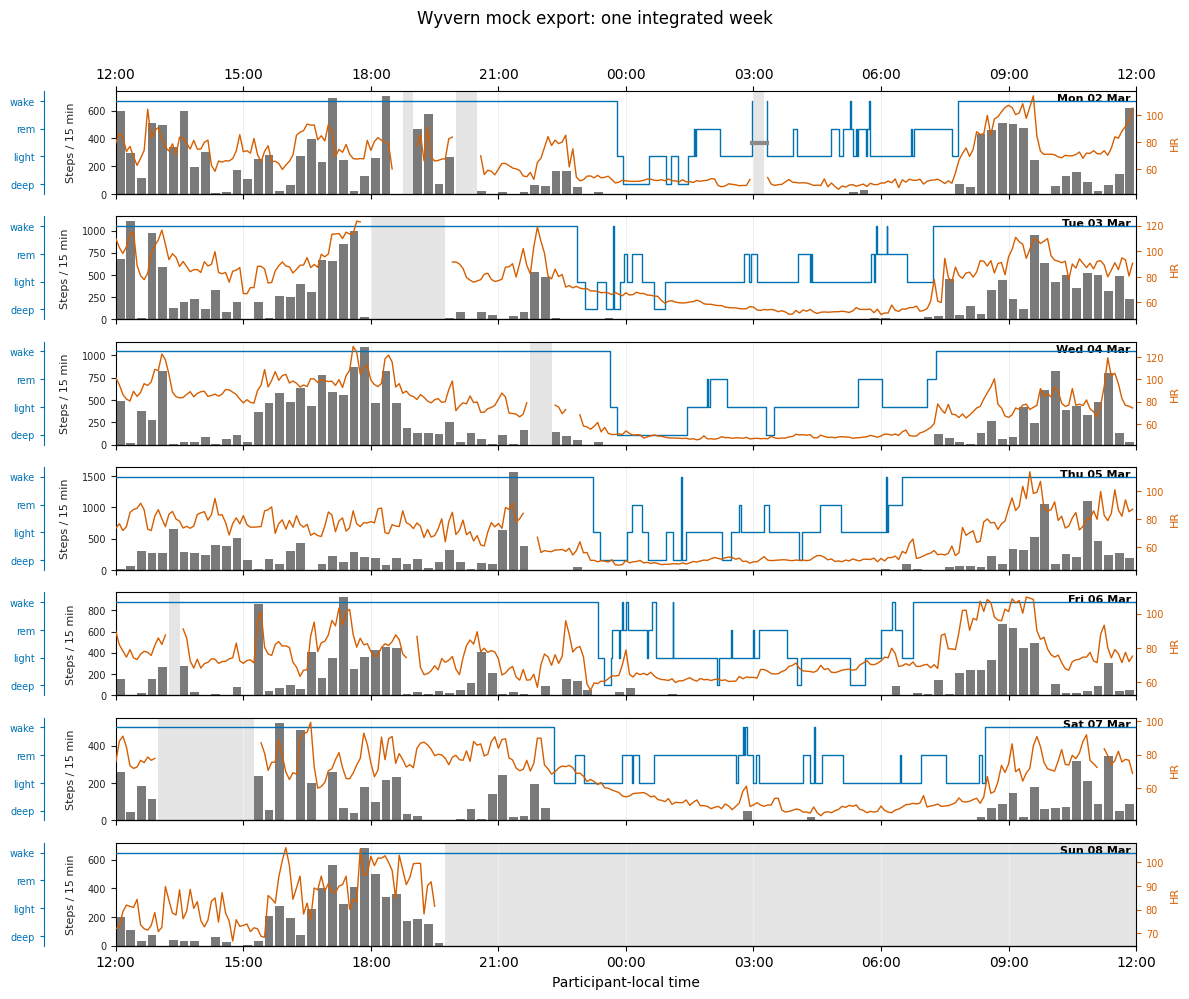

In [6]:
visualization.plot_weekly_overview(
    loader,
    participant,
    START,
    END,
    title="Wyvern mock export: one integrated week",
    show=False,
)
plt.show()

## Compare the provider-native scores

These scores remain provider-specific: pywearable can align and
aggregate them, but does not equate them with similarly named
scores from another device. A sleep-health score is absent when
no nightly sleep result is available; daytime strain can still be
present when activity data exists.

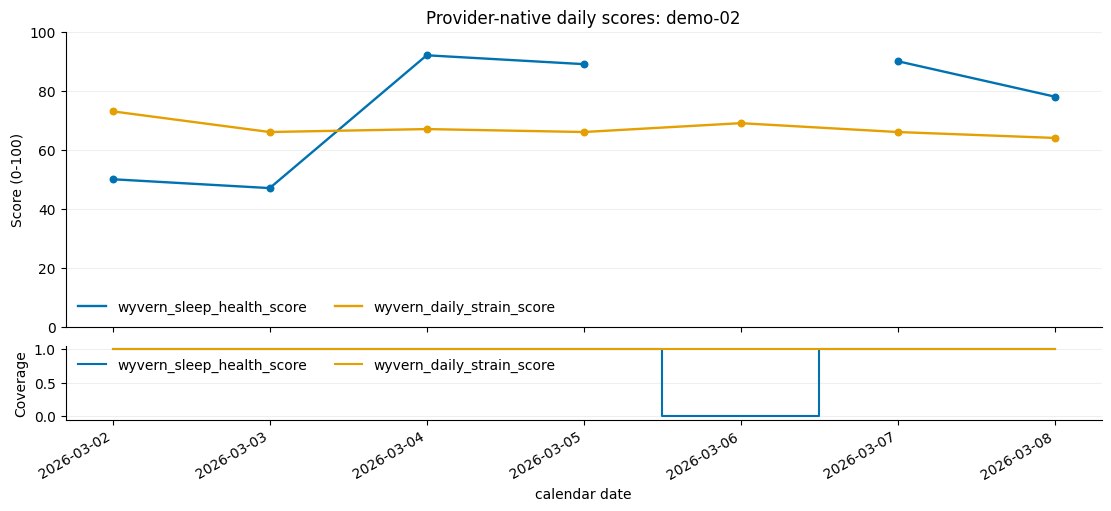

In [7]:
score_participant = "demo-02"
score_axes = visualization.plot_trajectory(
    daily_scores,
    [WYVERN_SLEEP_HEALTH_SCORE, WYVERN_DAILY_STRAIN_SCORE],
    user_id=score_participant,
    title=f"Provider-native daily scores: {score_participant}",
    ylabel="Score (0-100)",
    show_imputed=False,
    show_coverage=True,
    show=False,
)
score_axes["trajectory"].set_ylim(0, 100)
plt.show()

## Inspect nightly sleep

The compact sleep view uses the canonical summaries and native
stage intervals. Because the loader maps `sleepHealthScore` to
canonical `overall_sleep_score`, it can also be displayed beside
each night; unavailable nights and scores remain blank.

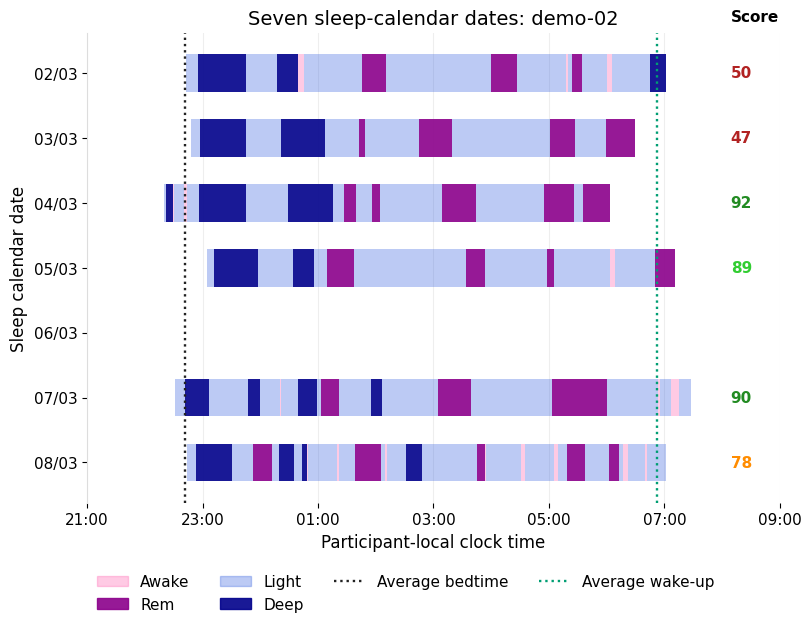

In [8]:
sleep_participant = "demo-02"
visualization.plot_sleep_summary(
    loader,
    sleep_participant,
    start_date=START,
    end_date=END - pd.Timedelta(days=1),
    show_scores=True,
    title=f"Seven sleep-calendar dates: {sleep_participant}",
    show=False,
)
plt.show()

## Inspect adherence across participants

To inspect adherence during the study, aggregate heart-rate
coverage into 10-minute windows and compare its local-time pattern
for each participant.

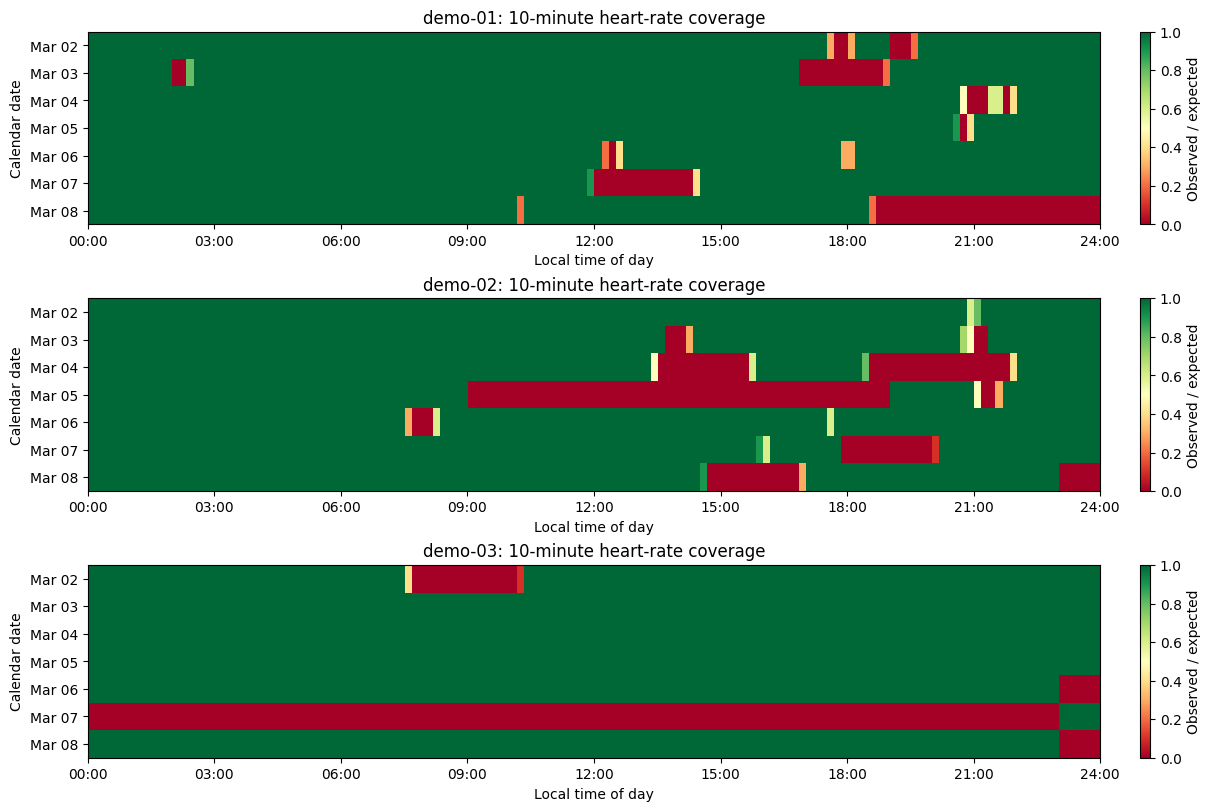

In [9]:
ten_minute_heart_rate = heart_rate.get_heart_rate_statistics(
    loader,
    statistic=heart_rate.HEART_RATE_STATISTIC_MEAN,
    user_id="all",
    start_date=START,
    end_date=END,
    resolution="10min",
)

participants = loader.get_user_ids()
fig, axes = plt.subplots(
    len(participants), 1, figsize=(12, 8), constrained_layout=True
)
for user_id, axis in zip(participants, axes):
    visualization.plot_coverage_heatmap(
        ten_minute_heart_rate,
        heart_rate.HEART_RATE_STATISTIC_MEAN,
        user_id=user_id,
        interval="10min",
        title=f"{user_id}: 10-minute heart-rate coverage",
        ax=axis,
        show=False,
    )
plt.show()

## What the adapter is responsible for

- Preserve the provider's native resolution and units.
- Expose UTC and local clocks only when they are known.
- Apply `[start_date, end_date)` consistently.
- Keep observed zero distinct from missing data.
- Return canonical empty frames for supported but empty intervals.
- Raise a clear error for unsupported provider-native features.
- Link every sleep-stage interval to a `sleep_summary_id`.
- Test duplicate records, timezone changes, empty intervals, and
  one end-to-end domain function for every implemented stream.

Once those responsibilities are met, downstream analysis remains
independent of the original source structure.